In [1]:
# import sys, importlib
# # Remove all cached hyperspot modules
# to_del = [k for k in sys.modules if 'hyperspot' in k]
# for k in to_del: del sys.modules[k]
# sys.path.insert(0, '/workspace/HyperSpot/hyperspot/src')
# import hyperspot.pipeline.evaluation as ev
# import inspect
# src = inspect.getsource(ev.ClusterEvaluation.compute_CT_baseline_scores)
# print('RUNNING VERSION - first line of function:')
# print(src.split('\n')[1])
# print('File:', ev.__file__)

In [2]:
# compute silhouette score of ST
# compute ss of ct-SVG
    # average ss

# average ss of ST and ct-SVG on all runs

# Moran's I of all SVGs in ST-orig
# Moran's I of all ct-SVGs in ST-decomp

# compute jaccard of ST

# union all ct-SVG for each cell type
    # compute jaccard

# Average Moran's I of all genes
# Average Moran's I on all runs
# Average jaccard score on all runs

import pandas as pd
import scanpy as sc
import torch

from sklearn.metrics import silhouette_score, silhouette_samples

from pathlib import Path

from hyperspot.preprocessing import common

from hyperspot.metadata import ProjectMetadata
from hyperspot.utils import (
    load_ct_spatial_data, 
    load_aggr_st_data
)

from hyperspot.pipeline.evaluation import ClusterEvaluation

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/numcodecs/__init__.py:106: DeprecationWarning: crc32c usage is deprecated since numcodecs v0.16.4. It is recommended to install google_crc32c instead.
  from numcodecs.checksum32 import CRC32, Adler32, JenkinsLookup3


In [3]:
spotiphy_proj_dir = Path("spotiphy_project_files") / "Human Kidney Cancer Core"

In [4]:
project_metadata = ProjectMetadata("hyperspot_project_files/Human Kidney Cancer Core")


In [5]:
cluster_eval = ClusterEvaluation()

In [6]:
st_baseline_scores = cluster_eval.compute_ST_baseline_scores()

/workspace/HGCTSVG/hgctsvg/src/hgctsvg/pipeline/evaluation.py:217: ImplicitModificationWarning: X should not be a np.matrix, use np.ndarray instead.
  adata_st.X = adata_st.X.todense()


In [7]:
st_baseline_scores

{'silhouette_pca': 0.1026100367307663,
 'silhouette_spatial': -0.11223860714174462}

In [8]:
ct_baseline_scores, mean_ct_baseline_scores = cluster_eval.compute_CT_baseline_scores(n_jobs=1)

In [9]:
ct_baseline_scores

{np.str_('B-cell'): {'silhouette_pca': 0.03993530571460724,
  'silhouette_spatial': -0.17033336406174512},
 np.str_('EC'): {'silhouette_pca': 0.03310320898890495,
  'silhouette_spatial': -0.34653678892350714},
 np.str_('Epi_PT'): {'silhouette_pca': 0.05391757935285568,
  'silhouette_spatial': -0.06911557755530398},
 np.str_('Epi_non-PT'): {'silhouette_pca': 0.06639450788497925,
  'silhouette_spatial': -0.20183017423907298},
 np.str_('Fibro'): {'silhouette_pca': 0.05118333920836449,
  'silhouette_spatial': -0.12366007798764578},
 np.str_('Mast'): {'silhouette_pca': 0.05765994265675545,
  'silhouette_spatial': -0.18413309981816672},
 np.str_('Myeloid'): {'silhouette_pca': -0.11323082447052002,
  'silhouette_spatial': -0.688727892574983},
 np.str_('NK'): {'silhouette_pca': -0.12052369117736816,
  'silhouette_spatial': 0.05492833432797726},
 np.str_('Plasma'): {'silhouette_pca': 0.050731759518384933,
  'silhouette_spatial': -0.0972859783072847},
 np.str_('RCC'): {'silhouette_pca': -0.01877

In [10]:
mean_ct_baseline_scores

{'silhouette_pca': np.float64(0.010357851007332405),
 'silhouette_spatial': np.float64(-0.2205011558259976)}

In [11]:
st_embedding_summary, st_embedding_run_scores = cluster_eval.compute_ST_embedding_scores()

/workspace/HGCTSVG/hgctsvg/src/hgctsvg/pipeline/evaluation.py:249: ImplicitModificationWarning: X should not be a np.matrix, use np.ndarray instead.
  adata_st.X = adata_st.X.todense()
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/numcodecs/__init__.py:106: DeprecationWarning: crc32c usage is deprecated since numcodecs v0.16.4. It is recommended to install google_crc32c instead.
  from numcodecs.checksum32 import CRC32, Adler32, JenkinsLookup3
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/numcodecs/__init__.py:106: DeprecationWarning: crc32c usage is deprecated since numcodecs v0.16.4. It is recommended to install google_crc32c instead.
  from numcodecs.checksum32 import CRC32, Adler32, JenkinsLookup3
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/numcodecs/__init__.py:106: DeprecationWarning: crc32c usage is deprecated since numcodecs v0.16.4. It is recommended to install google_crc32c instead.
  from numcodecs.checksum32 import CRC32, Adler32, JenkinsLookup3
/opt/

In [12]:
st_embedding_summary

{'silhouette_emb': {'mean': np.float64(0.060115079209208486),
  'std': np.float64(0.006271231783019914)},
 'silhouette_expr': {'mean': np.float64(-0.009891534835333005),
  'std': np.float64(0.010241351463907944)},
 'silhouette_spatial': {'mean': np.float64(-0.07813912969143295),
  'std': np.float64(0.022144448628976077)}}

In [13]:
st_embedding_run_scores

[{'silhouette_emb': 0.06362712383270264,
  'silhouette_expr': -0.01412771176546812,
  'silhouette_spatial': -0.05745578125970092},
 {'silhouette_emb': 0.05424656718969345,
  'silhouette_expr': -0.01605955697596073,
  'silhouette_spatial': -0.09949937734138259},
 {'silhouette_emb': 0.06177237629890442,
  'silhouette_expr': -0.01915024034678936,
  'silhouette_spatial': -0.05593324166184027},
 {'silhouette_emb': 0.06419280171394348,
  'silhouette_expr': -0.0018414240330457687,
  'silhouette_spatial': -0.09351444669481798},
 {'silhouette_emb': 0.07016071677207947,
  'silhouette_expr': 0.00773228332400322,
  'silhouette_spatial': -0.08688297061650564},
 {'silhouette_emb': 0.04847744479775429,
  'silhouette_expr': -0.023106103762984276,
  'silhouette_spatial': -0.08018470256735385},
 {'silhouette_emb': 0.06413677334785461,
  'silhouette_expr': 0.0006837460095994174,
  'silhouette_spatial': -0.09401865097543037},
 {'silhouette_emb': 0.05816708132624626,
  'silhouette_expr': -0.023261975497007

In [14]:
ct_embedding_summary, ct_embedding_run_scores = cluster_eval.compute_CT_embedding_scores(n_jobs=1)

In [15]:
ct_embedding_summary

[{np.str_('B-cell'): {'silhouette_emb': 0.1270211637020111,
   'silhouette_expr': -0.08314241468906403,
   'silhouette_spatial': -0.12193995804018733},
  np.str_('EC'): {'silhouette_emb': 0.05232113599777222,
   'silhouette_expr': -0.07736879587173462,
   'silhouette_spatial': -0.09911620398325105},
  np.str_('Epi_PT'): {'silhouette_emb': 0.09576775878667831,
   'silhouette_expr': -0.02864299714565277,
   'silhouette_spatial': -0.03844015810114436},
  np.str_('Epi_non-PT'): {'silhouette_emb': 0.12623725831508636,
   'silhouette_expr': -0.00509804580360651,
   'silhouette_spatial': -0.07186805894305215},
  np.str_('Fibro'): {'silhouette_emb': 0.14515356719493866,
   'silhouette_expr': 0.051409121602773666,
   'silhouette_spatial': -0.01506438584623455},
  np.str_('Mast'): {'silhouette_emb': 0.13611330091953278,
   'silhouette_expr': -0.018566105514764786,
   'silhouette_spatial': -0.19593362683736215},
  np.str_('Myeloid'): {'silhouette_emb': 0.027945151552557945,
   'silhouette_expr': 

In [16]:
ct_embedding_run_scores

{'silhouette_emb': {'mean': np.float64(0.09488562269834802),
  'std': np.float64(0.005817949648621066)},
 'silhouette_expr': {'mean': np.float64(-0.032694033379812026),
  'std': np.float64(0.005544813397361257)},
 'silhouette_spatial': {'mean': np.float64(-0.06843142193929423),
  'std': np.float64(0.011139767632344725)}}

## Spotiphy iscRNA + MICA baseline

Run the following **once** in the `scMiner` environment before executing the cell below:

```bash
conda run --no-capture-output -n scMiner python ../scripts/run_scminer_clustering.py \
    --iscRNA  spotiphy_project_files/Human\ Kidney\ Cancer\ Core/ST_decomposition.h5ad \
    --out_dir hyperspot_project_files/Human\ Kidney\ Cancer\ Core/scminer_clusters/
```

This produces per-CT cluster CSVs in `scminer_clusters/` which are then loaded below.

In [17]:
# import importlib
# import hyperspot.pipeline.evaluation
# importlib.reload(hyperspot.pipeline.evaluation)
# from hyperspot.pipeline.evaluation import ClusterEvaluation
# cluster_eval = ClusterEvaluation()

In [18]:
scminer_cluster_dir = project_metadata.project_folder / "scminer_clusters"
ct_spotiphy_scores, mean_ct_spotiphy_scores = cluster_eval.compute_CT_spotiphy_scores(scminer_cluster_dir)

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/numcodecs/__init__.py:106: DeprecationWarning: crc32c usage is deprecated since numcodecs v0.16.4. It is recommended to install google_crc32c instead.
  from numcodecs.checksum32 import CRC32, Adler32, JenkinsLookup3
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/numcodecs/__init__.py:106: DeprecationWarning: crc32c usage is deprecated since numcodecs v0.16.4. It is recommended to install google_crc32c instead.
  from numcodecs.checksum32 import CRC32, Adler32, JenkinsLookup3
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/numcodecs/__init__.py:106: DeprecationWarning: crc32c usage is deprecated since numcodecs v0.16.4. It is recommended to install google_crc32c instead.
  from numcodecs.checksum32 import CRC32, Adler32, JenkinsLookup3
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/numcodecs/__init__.py:106: DeprecationWarning: crc32c usage is deprecated since numcodecs v0.16.4. It is recommended to install google_cr

In [19]:
mean_ct_spotiphy_scores

{'silhouette_mica': np.float64(0.19944202758652033),
 'silhouette_spatial': np.float64(-0.02634444562801078)}

## HyperSpot vs scMINER: Homogeneity Analysis

In [20]:
from sklearn.metrics import homogeneity_score, completeness_score
import pandas as pd, numpy as np, re
from pathlib import Path

scminer_dir = project_metadata.project_folder / 'scminer_clusters'
ct_list = project_metadata.ct_list

results = []
for ct in ct_list:
    safe = re.sub(r'[^A-Za-z0-9_]', '_', ct)
    sm_csv  = scminer_dir / f'{safe}.csv'
    hg_csv  = project_metadata.eval_dir / 'run_0' / f'clusters_ct_{ct}.csv'
    if not sm_csv.exists() or not hg_csv.exists():
        continue

    sm = pd.read_csv(sm_csv, dtype={'cell_id': str}).set_index('cell_id')
    hg = pd.read_csv(hg_csv, index_col=0)
    hg.index = hg.index.astype(str)

    common = sm.index.intersection(hg.index)
    if len(common) < 2:
        continue

    sm_labels = sm.loc[common, 'cluster'].values
    hg_labels = hg.loc[common, 'domain'].values

    if len(np.unique(sm_labels)) < 2 or len(np.unique(hg_labels)) < 2:
        continue

    h = homogeneity_score(sm_labels, hg_labels)   # are HyperSpot domains within scMINER regions?
    c = completeness_score(sm_labels, hg_labels)   # does each scMINER region map to one HyperSpot domain?
    results.append({'ct': ct, 'n_sm': len(np.unique(sm_labels)),
                    'n_hg': len(np.unique(hg_labels)),
                    'homogeneity': h, 'completeness': c})

df_results = pd.DataFrame(results).set_index('ct')
print(df_results.round(3).to_string())
print(f'\nMean homogeneity:  {df_results["homogeneity"].mean():.3f}')
print(f'Mean completeness: {df_results["completeness"].mean():.3f}')

            n_sm  n_hg  homogeneity  completeness
ct                                               
B-cell         3     8        0.279         0.098
EC             7    12        0.387         0.281
Epi_PT         5     8        0.220         0.174
Epi_non-PT     4     9        0.401         0.251
Fibro          5     7        0.447         0.340
Mast           5     7        0.271         0.213
Myeloid        4     9        0.196         0.118
NK             2     3        0.021         0.013
RCC            7     6        0.111         0.132
T-cell         5     8        0.169         0.106
pDC            2     6        0.291         0.112

Mean homogeneity:  0.254
Mean completeness: 0.167


## Spatial Awareness Results

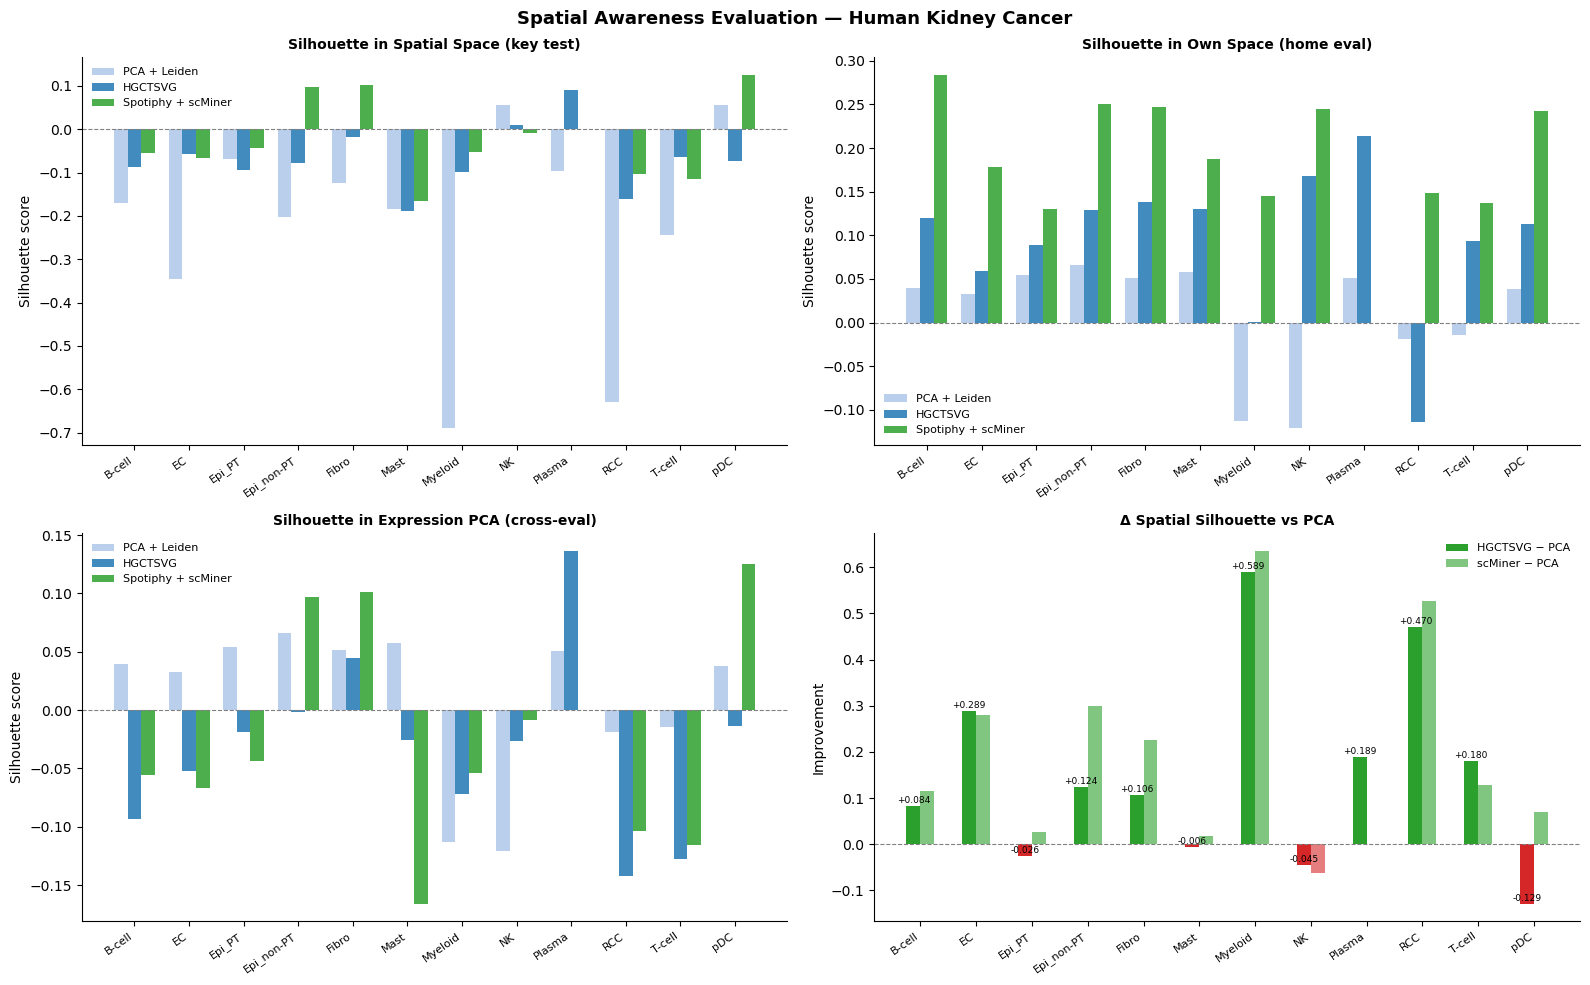

Mean Δ spatial (HGCTSVG − PCA): +0.1521
Mean Δ spatial (scMiner − PCA):  +0.2054


In [21]:
import matplotlib.pyplot as plt
import numpy as np

ct_list = project_metadata.ct_list

def _avg(run_list, ct, key):
    vals = [r[ct][key] for r in run_list if ct in r and key in r[ct]]
    return np.nanmean(vals) if vals else float('nan')

pca_spatial = [ct_baseline_scores.get(ct, {}).get('silhouette_spatial', float('nan')) for ct in ct_list]
pca_home    = [ct_baseline_scores.get(ct, {}).get('silhouette_pca',     float('nan')) for ct in ct_list]
hg_spatial  = [_avg(ct_embedding_summary, ct, 'silhouette_spatial') for ct in ct_list]
hg_home     = [_avg(ct_embedding_summary, ct, 'silhouette_emb')     for ct in ct_list]
hg_expr     = [_avg(ct_embedding_summary, ct, 'silhouette_expr')    for ct in ct_list]

# scMiner results (if available)
has_scminer = 'ct_spotiphy_scores' in dir() and ct_spotiphy_scores
sm_spatial  = [ct_spotiphy_scores.get(ct, {}).get('silhouette_spatial', float('nan')) for ct in ct_list] if has_scminer else [float('nan')] * len(ct_list)
sm_home     = [ct_spotiphy_scores.get(ct, {}).get('silhouette_mica',    float('nan')) for ct in ct_list] if has_scminer else [float('nan')] * len(ct_list)

x  = np.arange(len(ct_list))
w  = 0.25 if has_scminer else 0.35
n  = 3    if has_scminer else 2
offsets = np.linspace(-(n-1)/2, (n-1)/2, n) * w

methods     = ['PCA + Leiden', 'HyperSpot', 'Spotiphy + scMiner'] if has_scminer else ['PCA + Leiden', 'HyperSpot']
colors      = ['#aec7e8', '#1f77b4', '#2ca02c']

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('Spatial Awareness Evaluation — Human Kidney Cancer', fontsize=13, fontweight='bold')
axes = axes.flat

def grouped_bars(ax, vals_list, title, ylabel):
    for i, (vals, label, color) in enumerate(zip(vals_list, methods, colors)):
        ax.bar(x + offsets[i], vals, w, label=label, color=color, alpha=0.85)
    ax.axhline(0, color='grey', linewidth=0.8, linestyle='--')
    ax.set_xticks(x); ax.set_xticklabels(ct_list, rotation=35, ha='right', fontsize=8)
    ax.set_title(title, fontsize=10, fontweight='bold')
    ax.set_ylabel(ylabel)
    ax.legend(fontsize=8, frameon=False)
    ax.spines[['top','right']].set_visible(False)

grouped_bars(axes[0],
    [pca_spatial, hg_spatial] + ([sm_spatial] if has_scminer else []),
    'Silhouette in Spatial Space (key test)', 'Silhouette score')

grouped_bars(axes[1],
    [pca_home, hg_home] + ([sm_home] if has_scminer else []),
    'Silhouette in Own Space (home eval)', 'Silhouette score')

grouped_bars(axes[2],
    [pca_home, hg_expr] + ([sm_spatial] if has_scminer else []),
    'Silhouette in Expression PCA (cross-eval)', 'Silhouette score')

# Delta spatial
ax = axes[3]
delta_hg = [h - p if not (np.isnan(h) or np.isnan(p)) else float('nan') for h, p in zip(hg_spatial, pca_spatial)]
ax.bar(x - w/2, delta_hg, w, color=['#2ca02c' if d > 0 else '#d62728' for d in delta_hg], label='HyperSpot − PCA')
if has_scminer:
    delta_sm = [s - p if not (np.isnan(s) or np.isnan(p)) else float('nan') for s, p in zip(sm_spatial, pca_spatial)]
    ax.bar(x + w/2, delta_sm, w, color=['#2ca02c' if d > 0 else '#d62728' for d in delta_sm], alpha=0.6, label='scMiner − PCA')
ax.axhline(0, color='grey', linewidth=0.8, linestyle='--')
ax.set_xticks(x); ax.set_xticklabels(ct_list, rotation=35, ha='right', fontsize=8)
ax.set_title('Δ Spatial Silhouette vs PCA', fontsize=10, fontweight='bold')
ax.set_ylabel('Improvement'); ax.legend(fontsize=8, frameon=False)
ax.spines[['top','right']].set_visible(False)
for i, (d, xi) in enumerate(zip(delta_hg, x)):
    if not np.isnan(d):
        ax.text(xi - w/2, d + 0.002, f'{d:+.3f}', ha='center', va='bottom', fontsize=6.5)

plt.tight_layout()
plt.savefig('spatial_awareness_eval.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Mean Δ spatial (HyperSpot − PCA): {np.nanmean(delta_hg):+.4f}')
if has_scminer:
    print(f'Mean Δ spatial (scMiner − PCA):  {np.nanmean(delta_sm):+.4f}')

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/xarray_schema/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution


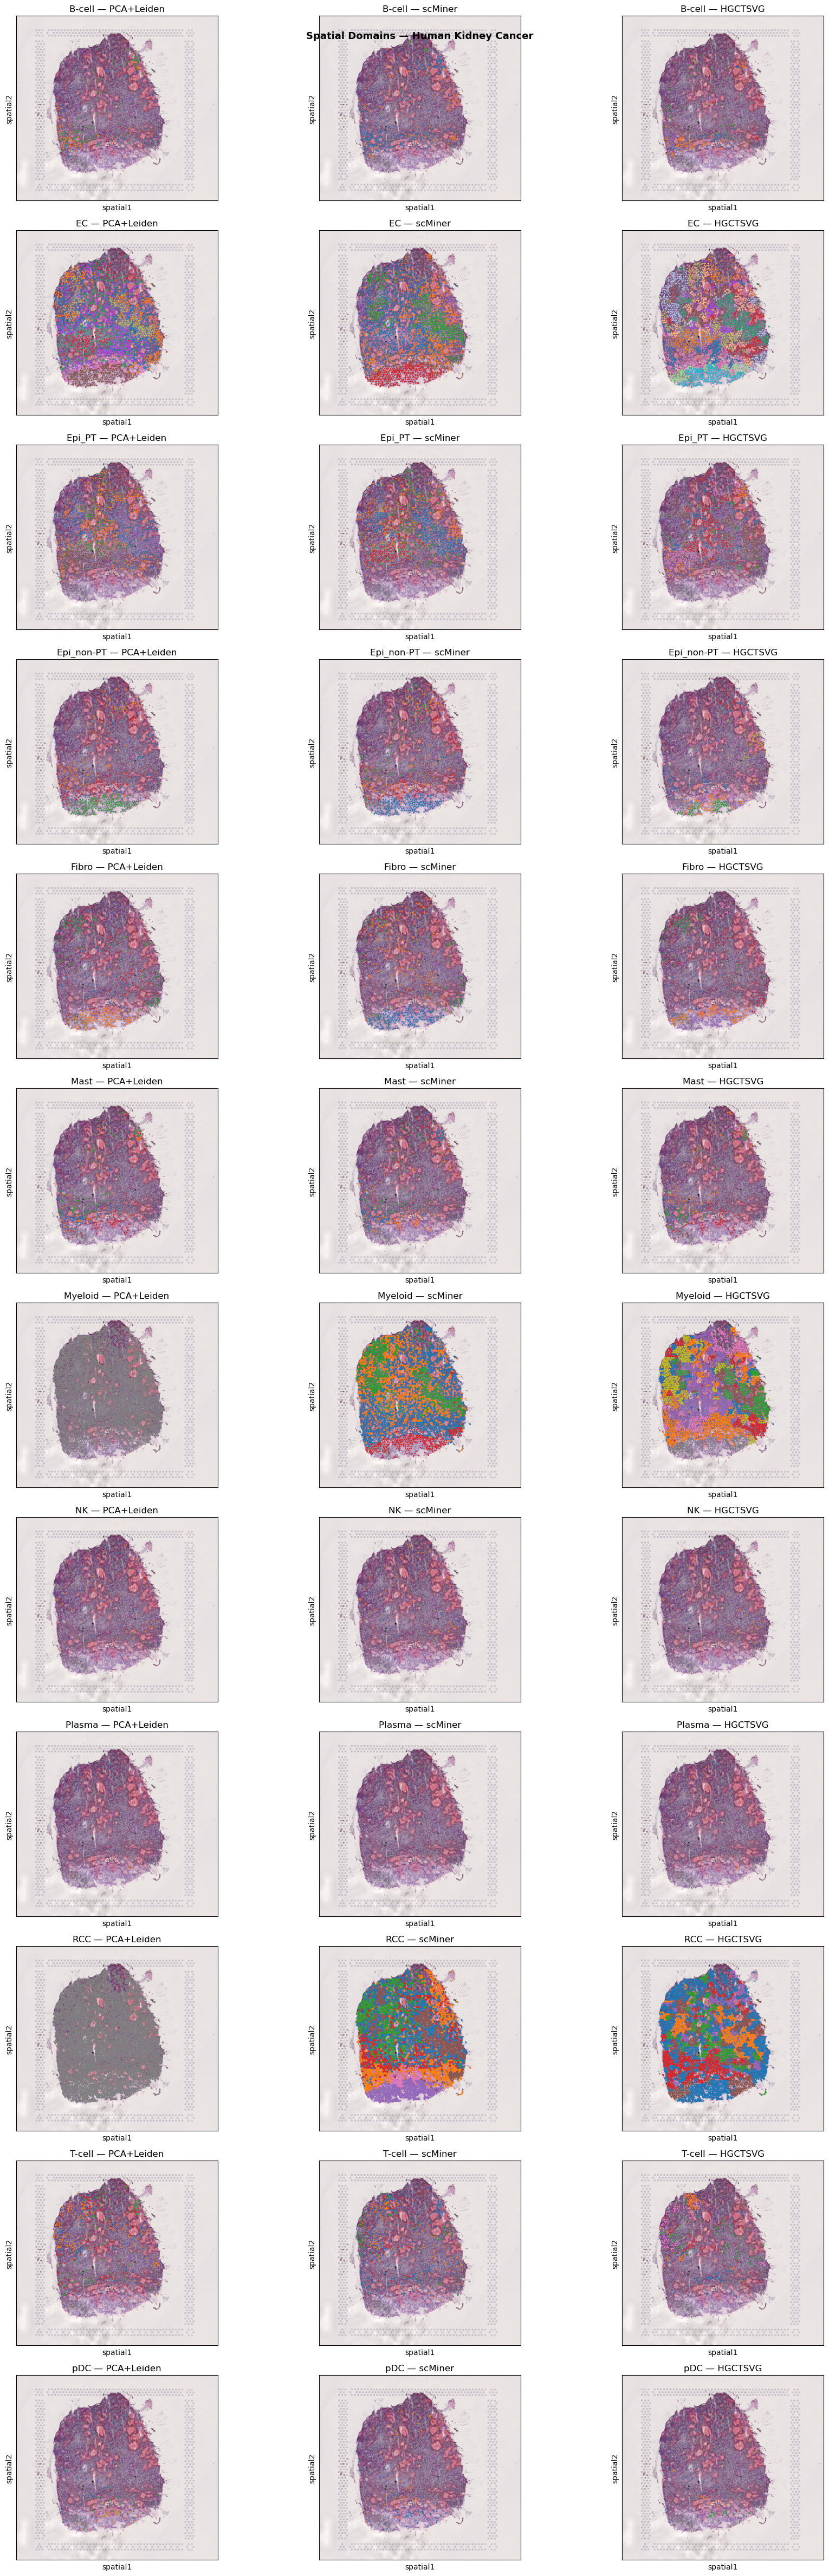

In [22]:
import squidpy as sq
import scanpy as sc
import pandas as pd
import re, numpy as np

scminer_dir = project_metadata.project_folder / 'scminer_clusters'
ct_list = project_metadata.ct_list
has_scminer = scminer_dir.exists()

fig, axes = plt.subplots(len(ct_list), 3, figsize=(18, 4 * len(ct_list)))
if len(ct_list) == 1: axes = axes[np.newaxis, :]
fig.suptitle('Spatial Domains — Human Kidney Cancer', fontsize=13, fontweight='bold')

for row, ct in enumerate(ct_list):
    adata_ct = load_ct_spatial_data(ct).copy()

    # --- PCA + Leiden ---
    ax = axes[row, 0]
    adata_pca = adata_ct.copy()
    n = max(1, min(50, adata_pca.n_obs - 1, adata_pca.n_vars - 1))
    sc.pp.pca(adata_pca, n_comps=n, mask_var=None)
    sc.pp.neighbors(adata_pca)
    sc.tl.leiden(adata_pca, flavor='igraph', n_iterations=2)
    adata_pca.obs['pca_domain'] = pd.Categorical(adata_pca.obs['leiden'])
    sq.pl.spatial_scatter(adata_pca, color='pca_domain', ax=ax,
                          title=f'{ct} — PCA+Leiden', legend_loc=None, size=1)

    # --- scMiner ---
    ax = axes[row, 1]
    safe = re.sub(r'[^A-Za-z0-9_]', '_', ct)
    sm_csv = scminer_dir / f'{safe}.csv'
    if sm_csv.exists():
        sm = pd.read_csv(sm_csv, dtype={'cell_id': str, 'cluster': str}).set_index('cell_id')
        common = adata_ct.obs_names.intersection(sm.index)
        if len(common) > 0:
            adata_sm = adata_ct[common].copy()
            adata_sm.obs['sm_domain'] = pd.Categorical(sm.loc[common, 'cluster'].values)
            sq.pl.spatial_scatter(adata_sm, color='sm_domain', ax=ax,
                                  title=f'{ct} — scMiner', legend_loc=None, size=1)
        else:
            # scMiner CSV exists but its cell_ids don't align with the current
            # decomposition for this cell type — re-run scMiner clustering on the
            # current ST_decomposition.h5ad to populate this panel.
            ax.text(0.5, 0.5, 'no overlap', ha='center', va='center', transform=ax.transAxes)
            ax.set_title(f'{ct} — scMiner (no overlap)', fontsize=9)
    else:
        ax.text(0.5, 0.5, 'pending', ha='center', va='center', transform=ax.transAxes)
        ax.set_title(f'{ct} — scMiner (pending)', fontsize=9)

    # --- HyperSpot ---
    ax = axes[row, 2]
    run_csv = project_metadata.eval_dir / 'run_0' / f'clusters_ct_{ct}.csv'
    if run_csv.exists():
        hg = pd.read_csv(run_csv, index_col=0)
        hg_aligned = hg.reindex(adata_ct.obs_names.astype(int))
        adata_ct.obs['hg_domain'] = pd.Categorical(hg_aligned['domain'].astype(str).values)
        sq.pl.spatial_scatter(adata_ct, color='hg_domain', ax=ax,
                              title=f'{ct} — HyperSpot', legend_loc=None, size=1)
    else:
        ax.text(0.5, 0.5, 'no clusters', ha='center', va='center', transform=ax.transAxes)
        ax.set_title(f'{ct} — HyperSpot (pending)', fontsize=9)

plt.tight_layout()
plt.savefig('spatial_domains_comparison.png', dpi=120, bbox_inches='tight')
plt.show()

## ct-SVG Stability & FDR Reports

Ported from the legacy self-evaluation notebook.
- **`ct_svg_stability_report`** — run-to-run stability (mean pairwise containment) of the union of per-cell-type SVG sets across the 10 evaluation runs.
- **`ct_svg_fdr_report`** — fraction of detected ct-SVGs passing a Moran's I spatial-autocorrelation test at FDR < 0.01.
- **`sepal_report`** — ranks the union of ct-SVGs by spatial structure using squidpy's Sepal diffusion score, run on the aggregated Visium hex grid. Sepal yields scores (not p-values), so there is no FDR.

In [23]:
from itertools import combinations
import pandas as pd
import numpy as np


def ct_svg_stability_report():
    runs = []
    lengths = []
    for run_id in range(10):
        svgs = set()
        for ct in project_metadata.ct_list:
            ct_run_dir = project_metadata.eval_dir / f"run_{run_id}"
            svgs_ct = pd.read_csv(ct_run_dir / f"svgs_ct_{ct}.csv")['Unnamed: 0']
            svgs = svgs | set(svgs_ct)
        runs.append(svgs)
        lengths.append(len(svgs))

    # pairwise containment
    scores = []
    for a, b in combinations(runs, 2):
        scores.append(len(a & b) / min(len(a), len(b)))

    print("per-run union sizes:", [len(run) for run in runs])
    print("n pairs:", len(scores))
    print("sum containment:", sum(scores))
    stability_score = sum(scores) / len(scores)
    print("ct-SVG stability score:", stability_score)
    return stability_score


ct_svg_stability_report()

per-run union sizes: [1210, 1122, 1151, 1198, 1247, 1259, 1245, 1263, 1192, 1239]
n pairs: 45
sum containment: 42.5302684726497
ct-SVG stability score: 0.9451170771699934


0.9451170771699934

In [24]:
import squidpy as sq
import pandas as pd
import numpy as np

from hyperspot.utils import load_ct_spatial_data


def ct_svg_fdr_report():
    run_id = 9

    significant_genes = []
    for ct in project_metadata.ct_list:
        adata_ct = load_ct_spatial_data(ct)
        ct_run_dir = project_metadata.eval_dir / f"run_{run_id}"
        svgs_ct = pd.read_csv(ct_run_dir / f"svgs_ct_{ct}.csv")['Unnamed: 0']

        if len(svgs_ct) == 0:
            continue

        # per-CT decomposed data is a point cloud, not a Visium grid, so build a
        # generic KNN spatial graph before computing Moran's I.
        sq.gr.spatial_neighbors(adata_ct, coord_type="generic", n_neighs=6)
        sq.gr.spatial_autocorr(
            adata_ct,
            mode="moran",
            genes=svgs_ct,
            n_perms=100,
        )

        moran_df = adata_ct.uns["moranI"]

        fdr_thresh = 0.01
        significant = (moran_df["pval_sim_fdr_bh"] < fdr_thresh)
        percent_significant = significant.mean() * 100

        print(f"{ct}: {percent_significant:.2f}% of genes pass FDR < {fdr_thresh}")
        significant_genes.append(percent_significant)

    print("average across all cell types:", np.mean(significant_genes))


ct_svg_fdr_report()

  0%|          | 0/100 [00:00<?, ?/s]

B-cell: 100.00% of genes pass FDR < 0.01


  0%|          | 0/100 [00:00<?, ?/s]

EC: 100.00% of genes pass FDR < 0.01


  0%|          | 0/100 [00:00<?, ?/s]

Epi_PT: 100.00% of genes pass FDR < 0.01


... (12 outputs left out)

  0%|          | 0/100 [00:00<?, ?/s]

T-cell: 100.00% of genes pass FDR < 0.01


  0%|          | 0/100 [00:00<?, ?/s]

pDC: 0.00% of genes pass FDR < 0.01
average across all cell types: 90.9090909090909


In [25]:
import squidpy as sq
import pandas as pd
import numpy as np

from hyperspot.utils import load_aggr_st_data


def sepal_report(run_id=9, max_neighs=6):
    """Rank the union of ct-SVGs by spatial structure using squidpy's Sepal.

    Sepal (Andersson et al., 2021) simulates a diffusion process on the spatial
    grid and returns a per-gene *score* (higher = more spatially structured) in
    ``adata.uns['sepal_score']``. It is a grid method, so it is run on the
    aggregated Visium hex-grid spots (``load_aggr_st_data``), not the per-cell-type
    decomposed point clouds. Note: Sepal produces scores, not p-values, so there is
    no FDR — "significance" here is relative ranking of the sepal score.
    """
    adata_aggr = load_aggr_st_data()

    # union of ct-SVGs detected in the chosen run, restricted to genes on the grid
    run_dir = project_metadata.eval_dir / f"run_{run_id}"
    svgs = set()
    for ct in project_metadata.ct_list:
        f = run_dir / f"svgs_ct_{ct}.csv"
        if f.exists():
            svgs |= set(pd.read_csv(f)['Unnamed: 0'])
    svgs = [g for g in svgs if g in adata_aggr.var_names]
    print(f"ct-SVGs evaluated on the Visium grid: {len(svgs)}")

    # Sepal requires a grid graph: hexagonal Visium -> max_neighs=6 (4 for square ST).
    sq.gr.spatial_neighbors(adata_aggr, coord_type="grid", n_neighs=6)
    sq.gr.sepal(adata_aggr, max_neighs=max_neighs, genes=svgs, n_jobs=8)

    scores = adata_aggr.uns["sepal_score"]
    s = scores["sepal_score"]
    print(f"sepal score across {len(s)} ct-SVGs -> "
          f"mean {s.mean():.3f}, median {s.median():.3f}, max {s.max():.3f}")
    print("\nTop 15 spatially structured ct-SVGs:")
    print(scores.head(15).to_string())
    return scores


sepal_report()

ct-SVGs evaluated on the Visium grid: 1239


  0%|          | 0/1239 [00:00<?, ?/s]

/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/opt/conda/envs/HGCTSVG/lib/python3.12/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable t

sepal score across 1239 ct-SVGs -> mean 0.844, median 0.793, max 7.997

Top 15 spatially structured ct-SVGs:
                 sepal_score
ENSG00000115457        7.997
ENSG00000163814        6.903
ENSG00000167123        6.459
ENSG00000171345        5.359
ENSG00000115641        5.010
ENSG00000181458        4.644
ENSG00000256235        4.131
ENSG00000019991        4.027
ENSG00000106333        3.454
ENSG00000151746        3.281
ENSG00000132329        3.229
ENSG00000134369        2.895
ENSG00000135919        2.665
ENSG00000000971        2.638
ENSG00000088992        2.516


,sepal_score
ENSG00000115457,7.997
ENSG00000163814,6.903
ENSG00000167123,6.459
ENSG00000171345,5.359
ENSG00000115641,5.010
...,...
ENSG00000198763,0.001
ENSG00000198888,0.001
ENSG00000198886,0.001
ENSG00000130203,0.001
